# 10.3 · A web app with Streamlit

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/10-deployment-mlops/03-streamlit/lesson.ipynb)

Read the [README](README.md) and open [app.py](app.py). This notebook checks the explanation maths against the bundle, then tests the real app with Streamlit's `AppTest`, which runs it without a browser. To use the app yourself, run `python -m streamlit run app.py` in a terminal from this folder.

In [1]:
# --- course files: found locally, downloaded on Colab -------------------------
import sys, urllib.request
from pathlib import Path
REPO_RAW = "https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/"

def repo_file(rel):
    """Return a local path to a file in this repo, downloading it if needed."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / rel).exists():
            return parent / rel
    dest = Path("course_files") / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists():
        urllib.request.urlretrieve(REPO_RAW + rel, dest)
    return dest

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
repo_file("data/download.py")                                  # churn_model finds the data through it
sys.path.insert(0, str(repo_file("lib/churn_model.py").parent))
import churn_model as cm

bundle = cm.load_bundle()          # trains and saves models/churn_bundle.joblib the first time
ROOT = cm.repo_root()
print(f"Model trained {bundle['trained']}, test AUC {bundle['metrics']['test_auc']}, "
      f"threshold {bundle['threshold']}")

Model trained 2026-10-28, test AUC 0.741, threshold 0.07


## 1. Contributions, by hand and in code

The README's table for the loyal customer, from the numbers inside the bundle.

In [2]:
scaler, logreg = bundle["pipeline"][0], bundle["pipeline"][-1]

def contributions(values):
    """Each feature's push on the log-odds: weight × standardised value."""
    z = (np.asarray(values, dtype=float) - scaler.mean_) / scaler.scale_
    return pd.Series(logreg.coef_[0] * z, index=bundle["features"])

def probability(values):
    return 1 / (1 + np.exp(-(logreg.intercept_[0] + contributions(values).sum())))

loyal = [10, 2000, 60, 300, 20]
c = contributions(loyal)
print(c.round(3))
print(f"log-odds {logreg.intercept_[0] + c.sum():.3f}  →  p = {probability(loyal):.4f}")

orders            -1.267
spend              0.005
products          -0.084
tenure_days       -0.274
days_since_last   -0.408
dtype: float64
log-odds -2.504  →  p = 0.0756


In [3]:
check = pd.DataFrame([dict(zip(bundle["features"], loyal))])
print("bundle:", round(float(bundle["pipeline"].predict_proba(check)[0, 1]), 4))

bundle: 0.0756


## 2. The chart the app draws

Bars to the right raise the risk, bars to the left lower it, compared with an average training customer. Two customers side by side: the 05.10 customer (52%) and the loyal one (8%).

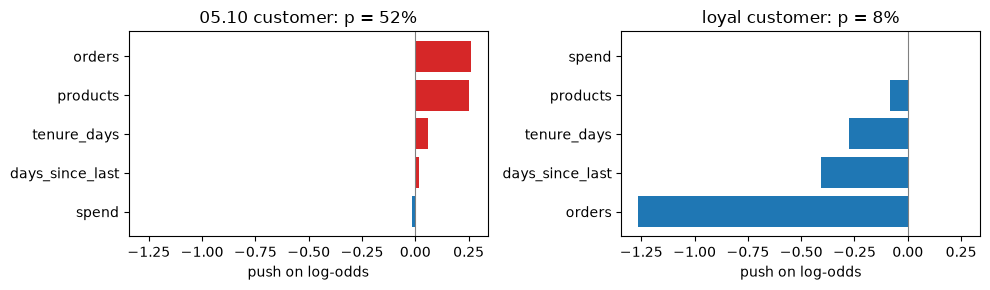

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
for ax, (name, values) in zip(axes, {"05.10 customer": [2, 310, 14, 150, 95], "loyal customer": loyal}.items()):
    c = contributions(values).sort_values()
    ax.barh(c.index, c, color=["tab:blue" if v < 0 else "tab:red" for v in c])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{name}: p = {probability(values):.0%}")
axes[0].set_xlabel("push on log-odds"); axes[1].set_xlabel("push on log-odds")
plt.tight_layout(); plt.show()

## 3. The decision rule

Break-even threshold = voucher cost ÷ lost margin. For the loyal customer at £5 / £60:

In [5]:
p = probability(loyal)
for voucher in [3, 5, 8]:
    t = voucher / 60
    print(f"£{voucher} voucher: break-even {t:.3f}, expected loss £{p * 60:.2f} → "
          f"{'voucher' if p > t else 'no voucher'}")
print(f"saved bundle threshold {bundle['threshold']} → {'voucher' if p >= bundle['threshold'] else 'no voucher'}")

£3 voucher: break-even 0.050, expected loss £4.53 → voucher
£5 voucher: break-even 0.083, expected loss £4.53 → no voucher
£8 voucher: break-even 0.133, expected loss £4.53 → no voucher
saved bundle threshold 0.07 → voucher


## 4. Test the real app

`AppTest.from_file` runs `app.py` exactly as `streamlit run` would, but in memory. We can read what is on the page and change widgets by their `key`.

In [6]:
from streamlit.testing.v1 import AppTest
from streamlit import logger as st_logger
st_logger.set_log_level("error")              # hide "missing ScriptRunContext": harmless outside a browser
import logging

def new_app(path, timeout=60):
    """A fresh AppTest, with Streamlit's harmless notices about running outside a browser hidden."""
    for name in list(logging.root.manager.loggerDict):
        if name.startswith("streamlit"):
            logging.getLogger(name).setLevel(logging.ERROR)
    return AppTest.from_file(path, default_timeout=timeout)

from streamlit.testing.v1 import AppTest
app_path = str(repo_file("modules/10-deployment-mlops/03-streamlit/app.py"))

def show(at):
    """What the retention team would see."""
    messages = [m.value for m in [*at.success, *at.info, *at.error]]
    risk = at.metric[0].value if len(at.metric) else "-"
    print(f"risk {risk} | {messages[0] if messages else ''}")

at = AppTest.from_file(app_path, default_timeout=60).run()
print("exceptions:", list(at.exception))
show(at)

exceptions: []
risk 52% | Send a £5 voucher: expected loss avoided £31.46 is more than its cost.


Type in the loyal customer:

In [7]:
for key, value in zip(["orders", "spend", "products", "tenure_days", "days_since_last"], loyal):
    at.number_input(key=key).set_value(value)
at.run()
show(at)

risk 8% | No voucher: expected loss £4.53 is less than the £5 voucher.


Back to the default customer, then make the voucher expensive:

In [8]:
for key, value in zip(["orders", "spend", "products", "tenure_days", "days_since_last"], [2, 310, 14, 150, 95]):
    at.number_input(key=key).set_value(value)
at.slider(key="voucher_cost").set_value(35).run()
show(at)
print([m.value for m in at.sidebar.markdown][-1])

risk 52% | No voucher: expected loss £31.46 is less than the £35 voucher.
Send a voucher when churn risk is above **58.3%** (voucher ÷ lost margin).


And an impossible customer, whose last order is before their first:

In [9]:
at.slider(key="voucher_cost").set_value(5)
at.number_input(key="days_since_last").set_value(200).run()
show(at)

risk - | Days since last order cannot be more than days since first order.


These four checks are a small automated test suite. Run them before every change to the app and you will know the page still works without clicking through it.

## Quiz answers

1. Streamlit reruns the whole script from the top with the new slider value and redraws the page.
2. Every interaction reruns the script; without caching, the model file would be loaded again on every click.
3. Together with the intercept $b_0$, they add up exactly to the log-odds; the sigmoid of that is the risk shown.
4. 8 / 60 = 0.133, about 13%.
5. The app uses the break-even rule (5/60 = 8.3%), the bundle the threshold chosen on data (7%). At 7.5% the bundle says voucher and the app says no.

**Next:** [10.4 Docker in one hour](../04-docker/) (optional) or [10.5 Experiment tracking with MLflow](../05-mlflow/)